#**Cargar librerías**
Lo primero que debemos hacer es cargar las librerías necesarias para la manipulación de nuestro conjunto de datos


In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
import piplite
await piplite.install('seaborn')

#**Cargar conjunto de datos**
Aquí debemos seleccionar el(los) conjunto(s) de datos.

In [7]:
df = pd.read_csv('Obesity Classification.csv')
df.head()

,ID,Age,Gender,Height,Weight,BMI,Label
0,1,25,Male,175,80,25.3,Normal Weight
1,2,30,Female,160,60,22.5,Normal Weight
2,3,35,Male,180,90,27.3,Overweight
3,4,40,Female,150,50,20.0,Underweight
4,5,45,Male,190,100,31.2,Obese


##Análisis rápido del conjunto de datos

In [8]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 108 entries, 0 to 107
Data columns (total 7 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   ID      108 non-null    int64  
 1   Age     108 non-null    int64  
 2   Gender  108 non-null    str    
 3   Height  108 non-null    int64  
 4   Weight  108 non-null    int64  
 5   BMI     108 non-null    float64
 6   Label   108 non-null    str    
dtypes: float64(1), int64(4), str(2)
memory usage: 5.1 KB


#**Tablas de frecuencia**

Creamos una tabla de frecuencias para la columna *Label*.

In [9]:
tab = df['Label'].value_counts().rename('frecuencia').to_frame()
tab.index.name = 'Label'
tab

,frecuencia
Label,
Underweight,47
Normal Weight,29
Overweight,20
Obese,12


In [10]:
tab =tab.reset_index()
tab

,Label,frecuencia
0,Underweight,47
1,Normal Weight,29
2,Overweight,20
3,Obese,12


## Frecuencia relativa

Agregamos la columna de frecuencia relativa.

In [11]:
#shape nos dice el tamaño, si usamos [0] nos da el número de renglones
#si usamos [1] nos da el número de columnas
df.shape[0]

108

In [12]:
tab['frecuencia_relativa'] = tab['frecuencia'] / df.shape[0]
tab

,Label,frecuencia,frecuencia_relativa
0,Underweight,47,0.435185
1,Normal Weight,29,0.268519
2,Overweight,20,0.185185
3,Obese,12,0.111111


In [ ]:
#round redondea al número de decimales indicado


Agregamos la columna de frecuencia porcentaje.

In [13]:
tab['frecuencia_relativa'] = round(tab['frecuencia_relativa'], 3)
tab

,Label,frecuencia,frecuencia_relativa
0,Underweight,47,0.435
1,Normal Weight,29,0.269
2,Overweight,20,0.185
3,Obese,12,0.111


## Frecuencia acumulada

In [14]:
tab['frecuencia_acumulada'] = tab['frecuencia'].cumsum()
tab

,Label,frecuencia,frecuencia_relativa,frecuencia_acumulada
0,Underweight,47,0.435,47
1,Normal Weight,29,0.269,76
2,Overweight,20,0.185,96
3,Obese,12,0.111,108


#**Histogramas**

In [ ]:
#El comando "unique" nos sirve para conocer los diferentes valores que hay en cada columna
df.Label.unique()

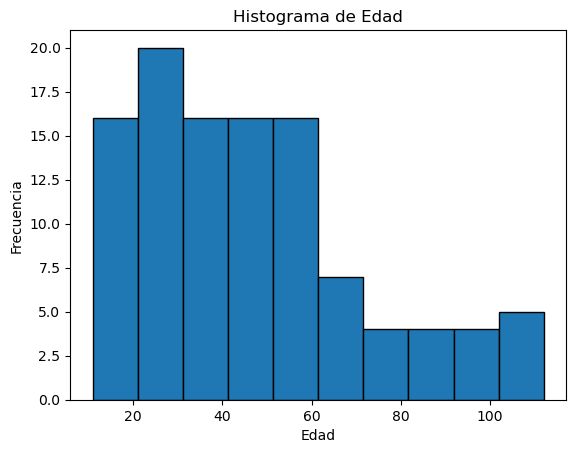

In [15]:
plt.hist(df['Age'], edgecolor='black')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.title('Histograma de Edad')
plt.show()

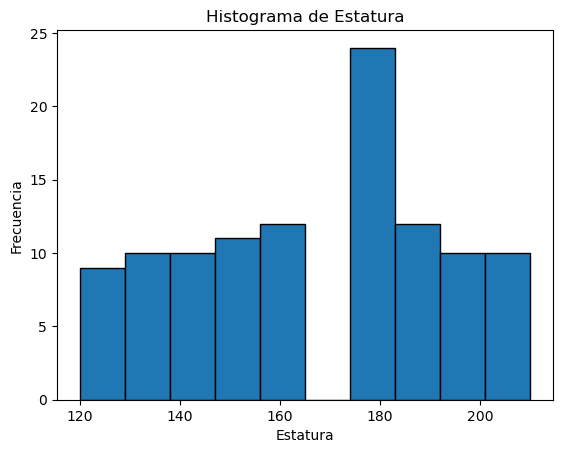

In [16]:
plt.hist(df['Height'], edgecolor='black')
plt.xlabel('Estatura')
plt.ylabel('Frecuencia')
plt.title('Histograma de Estatura')
plt.show()

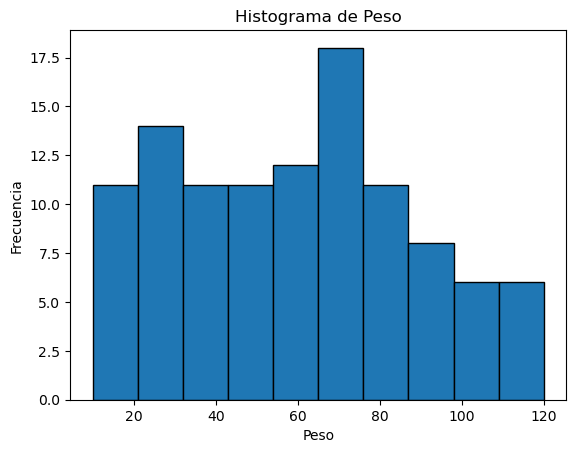

In [17]:
plt.hist(df['Weight'], edgecolor='black')
plt.xlabel('Peso')
plt.ylabel('Frecuencia')
plt.title('Histograma de Peso')
plt.show()

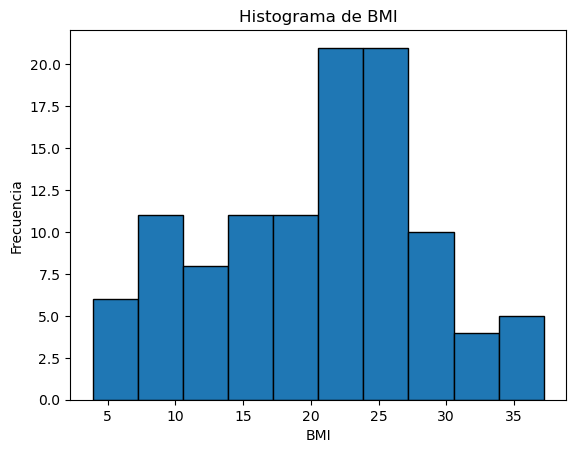

In [18]:
plt.hist(df['BMI'], edgecolor='black')
plt.xlabel('BMI')
plt.ylabel('Frecuencia')
plt.title('Histograma de BMI')
plt.show()

## Histogramas con filtros

Crearemos un histograma para la clase de *Obese*.

Filtramos los datos.

In [19]:
obeso = df.loc[(df['Label'] == 'Obese')]
obeso

,ID,Age,Gender,Height,Weight,BMI,Label
4,5,45,Male,190,100,31.2,Obese
6,7,55,Male,200,110,34.2,Obese
8,9,65,Male,210,120,37.2,Obese
16,17,48,Male,200,100,31.2,Obese
18,20,58,Male,210,110,34.2,Obese
24,26,88,Male,190,100,31.2,Obese
26,28,98,Male,200,110,34.2,Obese
28,30,108,Male,210,120,37.2,Obese
34,37,49,Male,200,105,28.9,Obese
36,39,59,Male,210,115,30.8,Obese


Creamos el histograma.

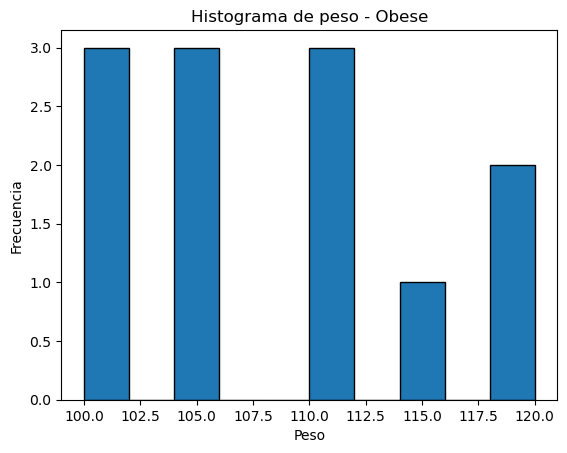

In [20]:
plt.hist(obeso['Weight'], edgecolor='black')
plt.xlabel('Peso')
plt.ylabel('Frecuencia')
plt.title('Histograma de peso - Obese')
plt.show()

Creamos un histograma para la clase *Underweight* separado por género.

Filtramos los datos.

In [21]:
bajo_peso = df.loc[(df['Label'] == 'Underweight')]
bajo_peso

,ID,Age,Gender,Height,Weight,BMI,Label
3,4,40,Female,150,50,20.0,Underweight
5,6,50,Female,140,40,16.7,Underweight
7,8,60,Female,130,30,13.3,Underweight
9,10,70,Female,120,20,10.0,Underweight
11,12,23,Female,160,50,20.0,Underweight
15,16,43,Female,140,50,20.0,Underweight
17,19,53,Female,130,40,16.7,Underweight
19,21,63,Female,120,30,13.3,Underweight
23,25,83,Female,150,50,20.0,Underweight
25,27,93,Female,140,40,16.7,Underweight


Crear el histograma.

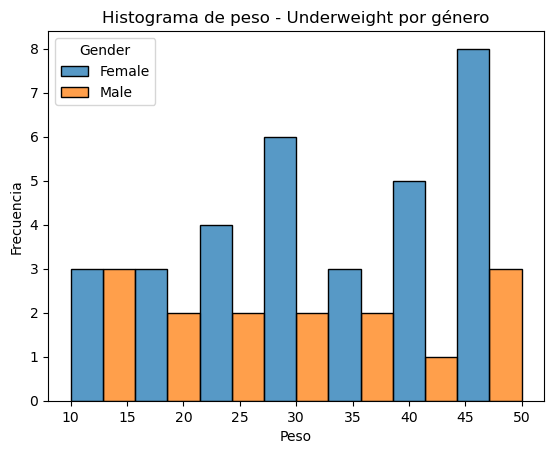

In [22]:
sns.histplot(data=bajo_peso, x='Weight', hue='Gender', multiple='dodge')
plt.xlabel('Peso')
plt.ylabel('Frecuencia')
plt.title('Histograma de peso - Underweight por género')
plt.show()

#**Gráfica circular**

Crear una gráfica circular para las clases de la columna *Label*.

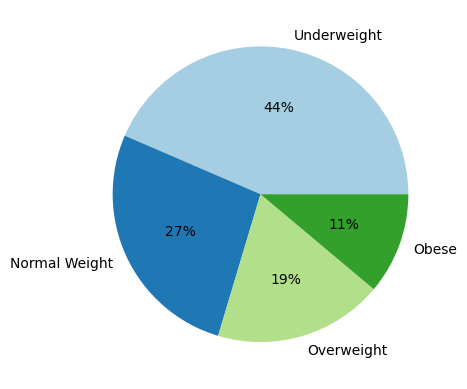

In [23]:
# Escogemos los colores que queremos utilizar
palette_color = sns.color_palette('Paired')

# Crear la gráfica con plt.pie
plt.pie(tab.frecuencia, labels=tab.Label, colors=palette_color, autopct='%.0f%%')

# Mostrar la gráfica
plt.show()

#**Polígono de frecuencias**

Crear un polígono de frecuencias para las clases de la columna Label.

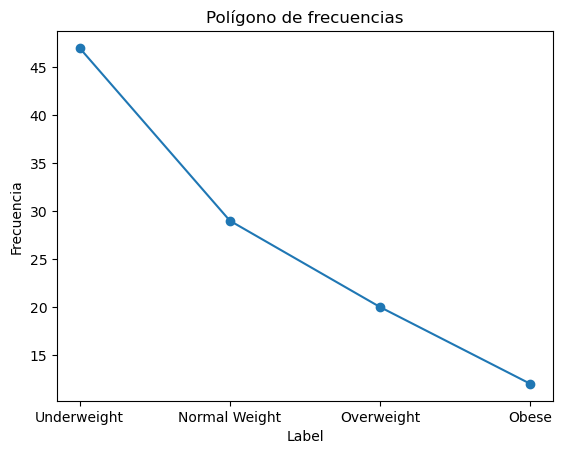

In [24]:
plt.plot(tab['Label'], tab['frecuencia'], marker='o')
plt.xlabel('Label')
plt.ylabel('Frecuencia')
plt.title('Polígono de frecuencias')
plt.show()

#**Diagrama de dispersión**

Hacer un diagrama de dispersión para ver si existe una correlación entre el peso y la edad.

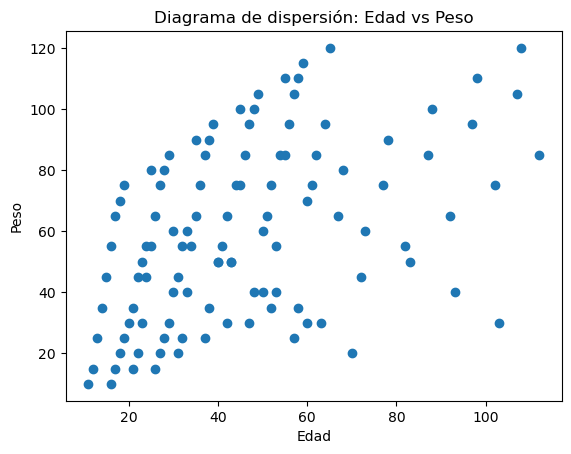

In [26]:
plt.scatter(df['Age'], df['Weight'])
plt.xlabel('Edad')
plt.ylabel('Peso')
plt.title('Diagrama de dispersión: Edad vs Peso')
plt.show()